# Stanford CS221 Artificial Intelligence: Principles and Techniques 2026

https://www.bilibili.com/video/BV1GxpQ6oEVk/?spm_id_from=333.1007.top_right_bar_window_default_collection.content.click&vd_source=014ef3a3e6c8bebacce399a9f644f4dd

https://github.com/stanford-cs221/lectures


## Basic Concepts


### tensor


In [8]:
! pip install numpy torch einops

Looking in indexes: https://mirrors.tuna.tsinghua.edu.cn/pypi/web/simple


In [9]:
import numpy as np
import torch

In [10]:
x = np.ones((5, 6))
print(np.triu(x))  # triangular upper matrix
print()
print(np.tril(x))  # triangular lower matrix

[[1. 1. 1. 1. 1. 1.]
 [0. 1. 1. 1. 1. 1.]
 [0. 0. 1. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1.]
 [0. 0. 0. 0. 1. 1.]]

[[1. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 0. 0.]
 [1. 1. 1. 0. 0. 0.]
 [1. 1. 1. 1. 0. 0.]
 [1. 1. 1. 1. 1. 0.]]


In [11]:
print(np.diag((1, 2, 3, 4)))  # diagonal matrix

[[1 0 0 0]
 [0 2 0 0]
 [0 0 3 0]
 [0 0 0 4]]


In [12]:
x = np.ones((5, 6))
print(x)
w = np.ones((6, 4))
print(w)
z = x @ w  # matrix multiplication
print(z)
z = torch.matmul(torch.tensor(x), torch.tensor(w))
print(z)
np.shape(z)

[[1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1.]]
[[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]]
[[6. 6. 6. 6.]
 [6. 6. 6. 6.]
 [6. 6. 6. 6.]
 [6. 6. 6. 6.]
 [6. 6. 6. 6.]]
tensor([[6., 6., 6., 6.],
        [6., 6., 6., 6.],
        [6., 6., 6., 6.],
        [6., 6., 6., 6.],
        [6., 6., 6., 6.]], dtype=torch.float64)


torch.Size([5, 4])

In [13]:
def matmul(x, w) -> np.ndarray:
    ans = np.zeros((x.shape[0], w.shape[1]))
    for i in range(0, x.shape[0]):
        for j in range(0, w.shape[1]):
            tmp = 0
            for k in range(0, x.shape[1]):
                tmp += x[i][k] * w[k][j]
            ans[i][j] = tmp
    return ans


print(matmul(x, w))

[[6. 6. 6. 6.]
 [6. 6. 6. 6.]
 [6. 6. 6. 6.]
 [6. 6. 6. 6.]
 [6. 6. 6. 6.]]


In [14]:
x = np.ones((3, 5, 6))
w = np.ones((6, 4))
print(x, "\n", w, "\n", x @ w)

[[[1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]]

 [[1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]]

 [[1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]
  [1. 1. 1. 1. 1. 1.]]] 
 [[1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]
 [1. 1. 1. 1.]] 
 [[[6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]]

 [[6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]]

 [[6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]
  [6. 6. 6. 6.]]]


In [15]:
import einops

# einops sum
x = torch.ones(3, 2, 3)  # batch seq1 hidden
y = torch.ones(3, 3, 4)  # batch hidden seq2
z = einops.einsum(x, y, "batch seq1 hidden, batch hidden seq2 -> batch seq1 seq2")
print(x)
print(y)
print(z)

tensor([[[1., 1., 1.],
         [1., 1., 1.]],

        [[1., 1., 1.],
         [1., 1., 1.]],

        [[1., 1., 1.],
         [1., 1., 1.]]])
tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])
tensor([[[3., 3., 3., 3.],
         [3., 3., 3., 3.]],

        [[3., 3., 3., 3.],
         [3., 3., 3., 3.]],

        [[3., 3., 3., 3.],
         [3., 3., 3., 3.]]])


In [16]:
# einops reduce
x = torch.ones((2, 3, 4))
# ... means: for every other layers, or all other dimensions remain
y = einops.reduce(x, "... hidden -> ...", "sum")  # x.sum(dim = -1)
print(x)
print(y)

tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])
tensor([[4., 4., 4.],
        [4., 4., 4.]])


In [17]:
# einops rearrange
x = torch.ones(3, 8)  # seq total_hidden
print("x = ", x)
w = torch.ones(4, 4)  # hidden1 hidden2

# (a b) means that they are actually in the same dimension
x = einops.rearrange(
    x, "... (heads hidden1) -> ... heads hidden1", heads=2
)  # 3*8 tensor -> 3*2*4 tensor (seq heads hidden1)
print("x = ", x)

x = einops.einsum(
    x, w, "... hidden1, hidden1 hidden2 -> ... hidden2"
)  # sum along the hidden1 dimension
print("w = ", w)
print("x = ", x)

x = einops.rearrange(x, "... heads hidden2 -> ... (heads hidden2)")
print(x)

x =  tensor([[1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1.]])
x =  tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.]]])
w =  tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
x =  tensor([[[4., 4., 4., 4.],
         [4., 4., 4., 4.]],

        [[4., 4., 4., 4.],
         [4., 4., 4., 4.]],

        [[4., 4., 4., 4.],
         [4., 4., 4., 4.]]])
tensor([[4., 4., 4., 4., 4., 4., 4., 4.],
        [4., 4., 4., 4., 4., 4., 4., 4.],
        [4., 4., 4., 4., 4., 4., 4., 4.]])


### Einstain Sumtation


In [18]:
x = np.array([0, 1, 10])
print(x)

[ 0  1 10]


In [19]:
y = einops.einsum(x, "i -> i")  # y[i] = x[i]
print(y)

[ 0  1 10]


In [20]:
y = einops.einsum(x, "i ->")  # y = sum(x[i])
print(y)

11


In [21]:
y = einops.einsum(x, x, "i, i -> i")  # y[i] = x[i] * x[i]
print(y)

[  0   1 100]


In [22]:
y = einops.einsum(x, x, "i, i ->")  # dot product: y += x[i] * x[i]
print(y)

101


In [23]:
y = einops.einsum(x, x, "i, j -> i j")  # outer product: y[i][j] = x[i] * x[j]
print(y)

[[  0   0   0]
 [  0   1  10]
 [  0  10 100]]


In [24]:
y = einops.einsum(x, x, x, "i, i, i -> i")  # y[i] = x[i] * x[i] * x[i]
print(y)

[   0    1 1000]


In [25]:
y = einops.einsum(
    x, x, x, "i, j, k -> i j k"
)  # outer product: y[i][j][k] = x[i] * x[j] * x[k]
print(y)

[[[   0    0    0]
  [   0    0    0]
  [   0    0    0]]

 [[   0    0    0]
  [   0    1   10]
  [   0   10  100]]

 [[   0    0    0]
  [   0   10  100]
  [   0  100 1000]]]


In [26]:
m = np.array([[1, 2, 3], [4, 5, 6]])
print(m)
print(m.shape)

[[1 2 3]
 [4 5 6]]
(2, 3)


In [27]:
y = einops.einsum(m, "i j ->")  # y += m[i][j]
print(y)

21


In [28]:
y = einops.einsum(m, "i j -> i")  # y[i] += m[i][j]
print(y)

[ 6 15]


In [29]:
y = einops.einsum(m, "i j -> j")  # y[j] += m[i][j]
print(y)

[5 7 9]


In [30]:
y = einops.einsum(m, "i j -> j i")  # y[j][i] = m[i][j], transpose
print(y)

[[1 4]
 [2 5]
 [3 6]]


In [31]:
print("x = ", x)
print("m = ", m)
y = einops.einsum(m, x, "i j, j -> i")  # y[i] += m[i][j] * x[j], vector product
print("y = ", y)

x =  [ 0  1 10]
m =  [[1 2 3]
 [4 5 6]]
y =  [32 65]


In [32]:
print(
    einops.einsum(m, m, "i k, j k -> i j")
)  # y[i][j] += m[i][k] * m[j][k], m \dot m^T
print()
print(
    einops.einsum(m, m, "k i, k j -> i j")
)  # y[i][j] += m[k][i] * m[k][j], m \dot m^T

[[14 32]
 [32 77]]

[[17 22 27]
 [22 29 36]
 [27 36 45]]


### gradient


gradient: the direction that decreases the function most.

$\nabla f = (\frac{\partial f}{\partial x}, \frac{\partial f}{\partial y}, \frac{\partial f}{\partial z}, ...)$


In [33]:
x = np.array([[1, 2, 0], [0, -1, 1]])
y = np.array([0, 3])  # target vector
w = np.array([1, 0, -1])  # weight vector

In [34]:
prediction = x @ w  # prediction = x * w
residuals = prediction - y
losses = residuals**2
total_loss = np.sum(losses)

### computation graphs


chain rule:
$\frac{\partial y}{\partial x} = \frac{\partial y}{\partial z} \cdot \frac{\partial z}{\partial x}$

for $\hat y=wx+b$, loss function: $L=(\hat y-y)^2$, we have a cumputation graph as follows:

Multiply($w$, $x$)

$\hat y$ = Add($wx$, $b$)

Loss($\hat y$, $y$)


#### Forward pass:

compute the value of each node in the graph, from input to output.

eg. $x=3, w=2, b=1, y=5$
$$z = wx + b = 2 \cdot 3 = 6$$
$$\hat y = z + b = 6 + 1 = 7$$
$$L = (\hat y - y)^2 = (7 - 5)^2 = 4$$


#### Backward pass

compute the gradient of each node in the graph, from output to input.

$$L=(\hat y - y)^2$$
$$\frac{\partial L}{\partial y} = 2(\hat y - y)=2(7 - 5)=4$$
$$\hat y = wx+b$$
$$\frac{\partial \hat y}{\partial w} = x=3, \frac{\partial \hat y}{\partial b} = 1$$
$$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial \hat y} \cdot \frac{\partial \hat y}{\partial w} = 4 \cdot 3 = 12$$
$$\frac{\partial L}{\partial b} = \frac{\partial L}{\partial \hat y} \cdot \frac{\partial \hat y}{\partial b} = 4 \cdot 1 = 4$$

PyTorch use `torch.autograd` to compute the gradient automatically.

The gradient of a leaf node represents how a change in that node will affect the root node (final output).


In [35]:
import torch

# 输入数据
x = torch.tensor(3.0)
target = torch.tensor(5.0)

# 需要学习的参数
w = torch.tensor(2.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

# Forward
y_hat = w * x + b
loss = (y_hat - target) ** 2

print("Prediction:", y_hat.item())  # 7.0
print("Loss:", loss.item())  # 4.0

# Backward
loss.backward()

print("dL/dw:", w.grad.item())  # 12.0
print("dL/db:", b.grad.item())  # 4.0

Prediction: 7.0
Loss: 4.0
dL/dw: 12.0
dL/db: 4.0


#### backpropagation


## Machine Learning


### Prediction task

**predictor**: A model that is used to make predictions, input -> output.

The **training data**: A set of **examples** used to train the model.

Each **example** consists of an (input, output) pair.

**hypothesis class**: A set of possible functions that map inputs to outputs. Also called **model architecture**.

**parameter**: A variable that controls the behavior of a model. Given a set of parameters, a model can make predictions.
eg. $y = w_1x_1 + w_2x_2 + b$, the parameters are $w_1, w_2, b$.

**Predictor** is a **model**

**Loss function**: A function that measures the difference between the predicted output and the actual output (in training data). The less the loss, the better the model is. We want to minimize the loss function.

**residual**: The difference between the predicted output and the actual output for a given example. $residual = y - \hat{y}$

**optimization algorithm**: To find the best parameters that minimize the loss function. eg. gradient descent, stochastic gradient descent, Adam, etc.


### Linear regression

The hypothesis class is linear funtions

```python
def squared_loss(params, example):
    x, y = example
    y_hat = params.weight * x + params.bias
    return (y_hat - y) ** 2
```

```python
def gradient_descent():
    training_data = get_training_data()
    params = Parameters1D(weight=0, bias=1)
    learning_rate = 0.01
    for epoch in range(num_epochs):
        train_loss = compute_loss(params, training_data)
        grad = compute_gradient(params, training_data)
        params = Parameters1D(
            weight=params.weight - learning_rate * grad.weight,
            bias=params.bias - learning_rate * grad.bias
            )
```


In [15]:
import torch
import matplotlib.pyplot as plt

In [22]:
torch.manual_seed(42)

# 1. Random data
X = torch.rand(100) * 10
y = 2 * X + 1 + torch.randn(100) * 2

In [23]:
# Model
def predict(X, w, b):
    return w * X + b


# Loss
def squared_loss(y_hat, y):
    return torch.mean((y_hat - y) ** 2)

In [24]:
# Parameters
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)
lr = 0.01

losses = []

In [25]:
# Training
for epoch in range(1000):
    # Forward
    y_hat = predict(X, w, b)
    loss = squared_loss(y_hat, y)
    losses.append(loss.item())

    # Backward (Autograd)
    loss.backward()

    # SGD
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    # Reset gradients
    w.grad.zero_()
    b.grad.zero_()

print(f"w = {w.item():.4f}, b = {b.item():.4f}")

w = 1.9091, b = 1.4519


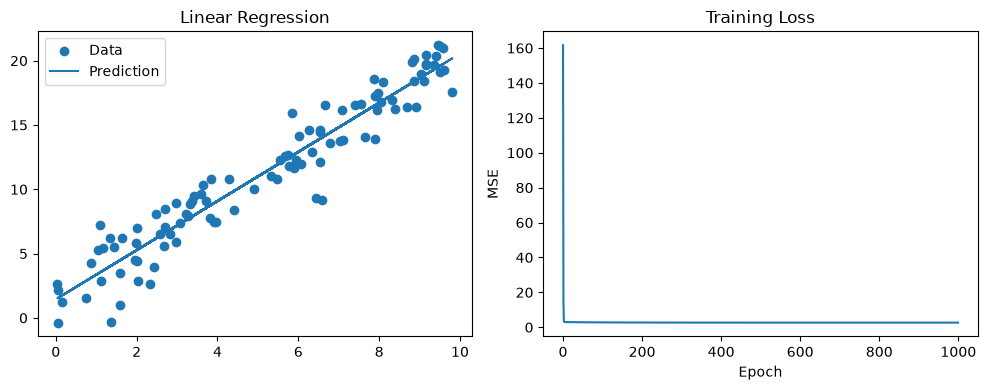

In [26]:
# Visualization
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].scatter(X.numpy(), y.numpy(), label="Data")
ax[0].plot(X.numpy(), predict(X, w, b).detach().numpy(), label="Prediction")
ax[0].set_title("Linear Regression")
ax[0].legend()

ax[1].plot(losses)
ax[1].set_title("Training Loss")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("MSE")

plt.tight_layout()
plt.show()

### Linear classification

input: images (a width x height x channels tensor), text (a string), etc.

output: binary classification, multiclass classification (k choices), etc.


#### binary classification

Squared loss is not suitable for classification tasks.

```python
def zero_one_loss_inline(example, params):
    # logit: the raw calculation result; its sign (+/-) is the prediction; its magnitude is the confidence of the prediction.
    logit = example.input @ params.weight + params.bias
    # example.output is either 1 or -1
    # margin: its sign is the correctness of the prediction
    # its magnitude measures the correctness of the prediction
    margin = logit * example.output
    loss = int(margin <= 0)
    return loss
# gradient of zero-one loss is always zero, so we cannot use gradient descent to optimize it.


def train_zero_one_loss(training_data, params):
    losses = []
    for example in training_data:
        total_loss += zero_one_loss_inline(example, params)
    train_loss = np.mean(losses)
    return train_loss

train_loss = train_zero_one_loss(training_data, params)
```

$logistic(x) = \frac{1}{1 + e^{-x}}$, maps $(-\infty, \infty)$ to $(0, 1)$, and is differentiable.

gradient:$\frac{d}{dx} logistic(x) = \frac{logistic(x)}{1-logistic(x)}$

**Maximum likelihood Principle**: to maximize the log probability of the training data.

For multiple examples, we should multiply the probabilities of each example, which is equivalent to adding the log probabilities of each example.
$$\prod p(y_i|x_i) \space or \space \sum log p(y_i|x_i)$$

```python
# to make a loss function that has gradient (continuous, differentiable)
# a logistic function is the standard choice
def logistic(x):
    return 1 / (1 + np.exp(-x))

def logistic_loss(example, params):
    # -inf to inf
    logit = example.input @ params.weight + params.bias
    prob_pos = logistic(logit)
    prob_neg = logistic(-logit) # equals to 1-logistic(logit)
    margin = logit * example.output
    prob_target = logistic(margin)
    loss = -np.log(prob_target)
    return loss

def train_logistic_loss(training_data, params):
    losses = []
    for example in training_data:
        total_loss += logistic_loss(example, params)
    train_loss = np.mean(losses)
    return train_loss

def gradient_logistic_loss(example, params):
    logit = example.input @ params.weight + params.bias
    margin = logit * example.output
    prob_target = logistic(margin)
    loss = -np.log(prob_target)
    # \frac{\partial}{\partial logit} loss
    grad_logit = -logistic(-margin)
    # \frac{\partial}{\partial weight} loss
    grad_weight = example.output * example.input * grad_logit
    # \frac{\partial}{\partial bias} loss
    grad_bias = example.output * grad_logit
    return Parameters(weight=grad_weight, bias=grad_bias)

def gradient_train_loss(params, training_data):
    grads = [gradient_logistic_loss(example, params) for example in training_data]
    mean_weight = np.mean([grad.weight for grad in grads], axis=0)
    mean_bias = np.mean([grad.bias for grad in grads], axis=0)
    return Parameters(weight=mean_weight, bias=mean_bias)

def gradient_descent(training_data, params, learning_rate=0.01, num_epochs=100):
    losses = []
    for epoch in range(num_epochs):
        train_loss = train_logistic_loss(training_data, params)
        grad = gradient_train_loss(params, training_data)
        params = Parameters(
            weight=params.weight - learning_rate * grad.weight,
            bias=params.bias - learning_rate * grad.bias
        )
        losses.append(train_loss)
```


In [27]:
! pip install matplotlib

Looking in indexes: https://mirrors.tuna.tsinghua.edu.cn/pypi/web/simple


In [30]:
import torch
from matplotlib import pyplot as plt

In [35]:
# Data: [x1, x2] -> class (0 or 1)
X = torch.tensor([[1.0, 1.0], [2.0, 1.0], [3.0, 3.0], [4.0, 3.0]])
y = torch.tensor([[-1.0], [-1.0], [1.0], [1.0]])

# Parameters
W = torch.randn(2, 1)
b = torch.zeros(1)

lr = 0.1

losses = []

In [36]:
def logistic(x):
    return 1 / (1 + torch.exp(-x))

In [ ]:
for epoch in range(200):
    # Forward
    logit = X @ W + b
    margin = logit * y
    prob = logistic(margin)

    # Logistic loss
    loss = -torch.log(prob).mean()
    losses.append(loss.item())

    # Backward (manual gradients)
    grad_logit = -y * logistic(-margin) / len(X)
    grad_W = X.T @ grad_logit
    grad_b = grad_logit.sum()

    # if use autograd, you can do:
    # loss.backward()
    # with torch.no_grad(): # to avoid autograd tracking SGD updates
    #     W -= lr * W.grad
    #     b -= lr * b.grad
    # W.grad.zero_()
    # b.grad.zero_()

    # SGD
    W -= lr * grad_W
    b -= lr * grad_b

# Predictions
logit = X @ W + b
prob_class1 = logistic(logit)

print("Logits:\n", logit)
print("Margins:\n", logit * y)
print("Class 1 probabilities:\n", prob_class1)
print("Classes:\n", (prob_class1 > 0.5).int())
print("W:", W)
print("b:", b)

Logits:
 tensor([[-0.9687],
        [-0.8363],
        [ 1.8825],
        [ 2.0150]])
Margins:
 tensor([[0.9687],
        [0.8363],
        [1.8825],
        [2.0150]])
Class 1 probabilities:
 tensor([[0.2751],
        [0.3023],
        [0.8679],
        [0.8824]])
Classes:
 tensor([[0],
        [0],
        [1],
        [1]], dtype=torch.int32)
W: tensor([[0.1325],
        [1.2932]])
b: tensor([-2.3943])


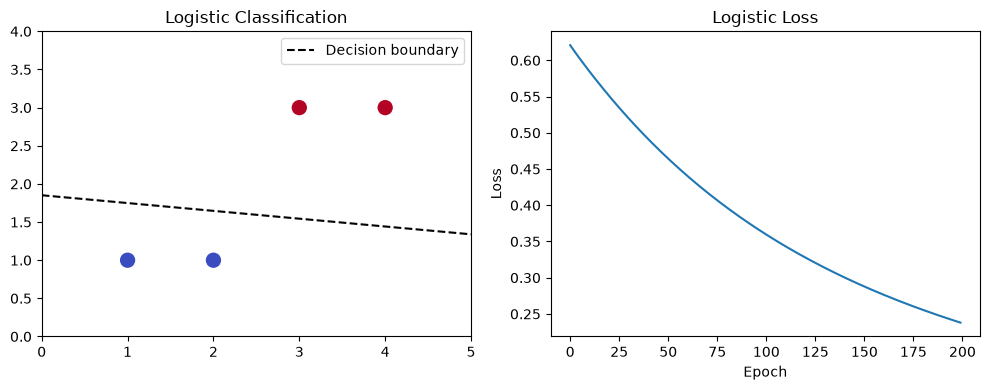

In [38]:
# Visualization
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# 1. Classification
ax[0].scatter(X[:, 0], X[:, 1], c=y.flatten(), cmap="coolwarm", s=100)

# Decision boundary: logit = 0
x_line = torch.linspace(0, 5, 100)
y_line = -(W[0, 0] * x_line + b) / W[1, 0]

ax[0].plot(x_line, y_line, "k--", label="Decision boundary")
ax[0].set(xlim=(0, 5), ylim=(0, 4), title="Logistic Classification")
ax[0].legend()

# 2. Loss curve
ax[1].plot(losses)
ax[1].set(xlabel="Epoch", ylabel="Loss", title="Logistic Loss")

plt.tight_layout()
plt.show()

#### Multiclass classification

output $y \in \{0, 1, ..., k-1\}$


In [40]:
import torch
import numpy as np

In [42]:
# 1. Generate 3 classes
X = np.vstack(
    [
        np.random.randn(100, 2) + [-2, -2],
        np.random.randn(100, 2) + [2, -2],
        np.random.randn(100, 2) + [0, 2],
    ]
)
y = np.repeat([0, 1, 2], 100)

X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

In [ ]:
W = torch.zeros(2, 3, requires_grad=True)  # 2 * 3 weight matrix
b = torch.zeros(3, requires_grad=True)
lr = 0.1

W: tensor([[0., 0., 0.],
        [0., 0., 0.]], requires_grad=True)


**Softmax function**: to map the logits to probabilities, which sum to 1.

softmax(logits) = softmax(logits + k) for any constant k

```python
def softmax(logits):
    exp_logits = np.exp(logits)
    probs = exp_logits / np.sum(exp_logits)
    return probs
```


**cross entropy** measures the difference between two probability distributions.

```python
terms = target_probs * -np.log(predicted_probs)
cross_entropy = np.sum(terms)
```

In practice, we use one-hot vector for target. In this case, the cross entropy loss is simply the negative log probability of the target class.

```python
def cross_entropy_loss(example, params):
    logits = example.input @ params.weight + params.bias
    probs = softmax(logits)
    target_class = example.output
    cross_entropy = -np.log(probs[target_class])
    return cross_entropy
```

We can use gradient descent to optimize the cross entropy loss function.


#### Representing Text

1. Tokenization: convert a string into a sequence of integers.

   eg. "I love AI" -> [1, 2, 3], where 1 is the index of "I", 2 is the index of "love", and 3 is the index of "AI".

2. Representation: convert a sequence of integers into a one-hot vector.

   eg. [1, 2, 3] -> [[1, 0, 0], [0, 1, 0], [0, 0, 1]], where each row is a one-hot vector of the corresponding integer.

Language models use more sophisticated tokenizers eg. Byte-Pair Encoding introduced by GPT-2.

**Bag of words representation**
Average the row one-hot vectors of the words in the text to get a single vector representation of the text.

eg. "I love AI" -> [[1, 0, 0], [0, 1, 0], [0, 0, 1]] -> [1/3, 1/3, 1/3]

- pro: does not depend on the length of the text
- con: does not pay attention to the order of the words in the text


### switch to PyTorch / JAX


In [44]:
import torch

In [ ]:
x = torch.tensor(
    [1.0, 2, 3], requires_grad=True
)  # to tract the gradient of x using autograd
# use 1. instead of 1 for float, otherwise it will be treated as int and cannot compute gradient
y = torch.tensor([4.0, 5, 6], requires_grad=True)
z = x @ y  # or z = torch.matmul(x, y); automatically forward() here
z.backward()  # compute the gradient of z with respect to x and y

print("x=", x)
print("y=", y)
print("z=", z)
print("x.grad=", x.grad)  # should be y
print("y.grad=", y.grad)  # should be x

x= tensor([1., 2., 3.], requires_grad=True)
y= tensor([4., 5., 6.], requires_grad=True)
z= tensor(32., grad_fn=<DotBackward0>)
x.grad= tensor([4., 5., 6.])
y.grad= tensor([1., 2., 3.])


In PyTorch,

- torch.tensor are nodes in the computation graph
- Operation (including @) are parallel to numpy
- some names are different (eg. `torch.tensor` vs `np.array`)
- Computation done when constructing the computation graph. eg. `x @ y` itself calls `forward()`
- Call `torch.tensor.backward()` to compute/backpropagate the gradient `torch.tensor.grad` of the root node recursively
- Specify `requires_grad=True` to tell PyTorch to compute the gradient of this tensor (parameters).

To use a node,

- use the node directly so new values will backprop through the node
- use the node's value. new values will not backprop.

```python
# to use the node value
z = y.detach() ** 2 + x
z.backward()
# this will not backprop through y, but will backprop through x
# or
with torch.no_grad(): # only compute forward()
    z = y ** 2 + x
z.backward() # will rise a RuntimeError
```

PyTorch has many built-in

- models
- loss functions
- optimizers
- ...


In [ ]:
# One-step update example
import torch

# Data
x = torch.tensor([1.0, 2, 3, 4])
target_y = torch.tensor([0.0, 1, 0])

print("x=", x)
print("target_y=", target_y)

# Linear model
torch.manual_seed(42)
model = torch.nn.Linear(
    4, 3
)  # input_dim=4, output_dim=3; a weight matrix of shape (4, 3) and a bias vector of shape (3,) will be created
logits = model(x)  # calculate the logits (raw scores) for each class

print("model.weight=", model.weight)
print("model.bias=", model.bias)
print("logits=", logits)

# Loss function
cross_entropy = (
    torch.nn.CrossEntropyLoss()
)  # it compares predicted **logits** (not the probabilities) and target distribution. so no softmax needed.
loss = cross_entropy(logits, target_y)
loss.backward()

print("loss=", loss.item())
print("model.weight=", model.weight)
print("model.bias=", model.bias)
print("model.weight.grad=", model.weight.grad)
print("model.bias.grad=", model.bias.grad)

# Optimizer
# SGD: stochastic gradient descent
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
optimizer.step()  # update the model parameters

print("model.weight=", model.weight)
print("model.bias=", model.bias)

logits = model(x)
print("logits=", logits)

x= tensor([1., 2., 3., 4.])
target_y= tensor([0., 1., 0.])
model.weight= Parameter containing:
tensor([[ 0.3823,  0.4150, -0.1171,  0.4593],
        [-0.1096,  0.1009, -0.2434,  0.2936],
        [ 0.4408, -0.3668,  0.4346,  0.0936]], requires_grad=True)
model.bias= Parameter containing:
tensor([0.3694, 0.0677, 0.2411], requires_grad=True)
logits= tensor([3.0675, 0.6042, 1.6264], grad_fn=<ViewBackward0>)
loss= 2.742263078689575
model.weight= Parameter containing:
tensor([[ 0.3823,  0.4150, -0.1171,  0.4593],
        [-0.1096,  0.1009, -0.2434,  0.2936],
        [ 0.4408, -0.3668,  0.4346,  0.0936]], requires_grad=True)
model.bias= Parameter containing:
tensor([0.3694, 0.0677, 0.2411], requires_grad=True)
model.weight.grad= tensor([[ 0.7565,  1.5131,  2.2696,  3.0261],
        [-0.9356, -1.8712, -2.8067, -3.7423],
        [ 0.1790,  0.3581,  0.5371,  0.7162]])
model.bias.grad= tensor([ 0.7565, -0.9356,  0.1790])
model.weight= Parameter containing:
tensor([[ 0.3066,  0.2637, -0.3441,  0.1

For a complete training process


In [49]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from dataclasses import dataclass
from IPython.display import clear_output, display

In [64]:
# 1. Define Example
@dataclass
class Example:
    x: torch.Tensor
    y: int


# 2. Generate training data (3 classes)
torch.manual_seed(42)

training_data = []
centers = [[-2, -2], [2, -2], [0, 2]]

for label, center in enumerate(centers):
    for i in range(5):
        x = torch.tensor(center, dtype=torch.float32)
        x = x + torch.randn(2) * 0.8
        training_data.append(Example(x, label))


# 4. Visualization function
def visualize(model, x, y, losses, step, num_steps):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))

    # Decision regions
    xx, yy = np.meshgrid(np.linspace(-5, 5, 100), np.linspace(-5, 5, 100))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

    with torch.no_grad():
        regions = model(grid).argmax(dim=1)
        regions = regions.numpy().reshape(xx.shape)

    ax[0].contourf(
        xx, yy, regions, levels=[-0.5, 0.5, 1.5, 2.5], cmap="viridis", alpha=0.3
    )
    ax[0].scatter(x[:, 0], x[:, 1], c=y, cmap="viridis", s=20, vmin=0, vmax=2)
    ax[0].set(xlim=(-5, 5), ylim=(-5, 5), title=f"Decision Boundary - Step {step}")

    # Loss curve
    ax[1].plot(losses)
    ax[1].set(xlabel="Step", ylabel="Loss", title="Training Loss")
    ax[1].set_xlim(0, num_steps)
    ax[1].set_ylim(bottom=0)

    plt.tight_layout()
    clear_output(wait=True)
    display(fig)
    plt.close(fig)

In [66]:
def train_model(
    model: nn.Module,
    training_data: list[Example],
    optimizer_class=torch.optim.SGD,
    num_steps=80,
    learning_rate=0.1,
):
    # make all the training data into a single tensor for x and y for efficiency
    x = torch.stack([example.x for example in training_data])
    target_y = torch.tensor([example.y for example in training_data])
    cross_entropy = torch.nn.CrossEntropyLoss()
    losses: list[float] = []
    optimizer = optimizer_class(model.parameters(), lr=learning_rate)
    for step in range(num_steps):
        # Forward
        logits = model(x)
        loss = cross_entropy(logits, target_y)
        losses.append(loss.item())

        # Backward
        optimizer.zero_grad()  # reset the gradients to zero before backward pass, remember to do this!!
        loss.backward()

        # Update the model parameters
        optimizer.step()

        visualize(model, x, target_y, losses, step + 1, num_steps)

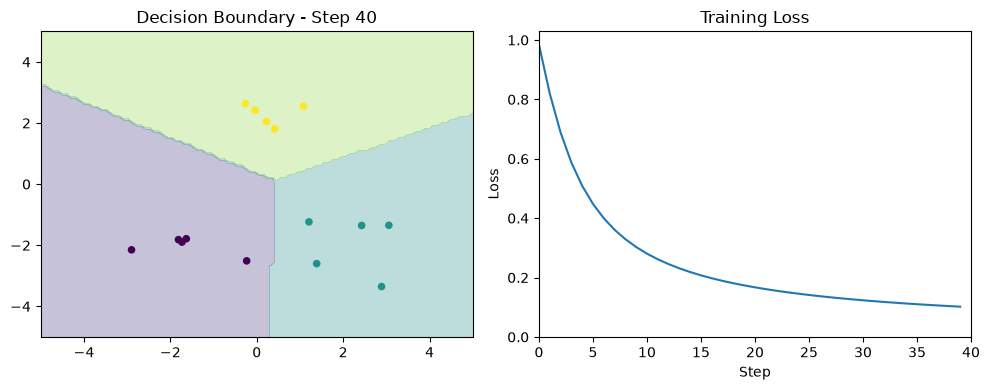

Accuracy: 100.00%
Weights: Parameter containing:
tensor([[-0.6548, -0.7742],
        [ 0.9308, -0.8092],
        [ 0.2032,  0.7100]], requires_grad=True)
Bias: Parameter containing:
tensor([ 0.3114, -0.3404, -0.2254], requires_grad=True)
logits: tensor([[ 2.9132, -0.4162, -1.9238],
        [ 2.9039, -0.5581, -1.8828],
        [ 3.8729, -1.2991, -2.3400],
        [ 2.4078,  1.4738, -2.0551],
        [ 2.7619, -0.4128, -1.8248],
        [-0.2312,  3.0141, -0.6924],
        [ 1.0153,  5.0605, -2.0183],
        [ 0.4750,  1.7831, -0.8557],
        [-0.6484,  3.5953, -0.5600],
        [ 1.4164,  3.0554, -1.7898],
        [-2.3705, -1.3959,  1.8041],
        [-1.5576, -2.7175,  1.5927],
        [-1.4192, -1.7855,  1.2722],
        [-1.3631, -1.4153,  1.1441],
        [-1.5368, -2.3367,  1.4853]])
Predictions: tensor([0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2])


In [67]:
# 3. Define model
model = nn.Linear(2, 3)

# 6. Train
losses = train_model(model, training_data, num_steps=40)

# 7. Accuracy
x = torch.stack([example.x for example in training_data])
y = torch.tensor([example.y for example in training_data])

with torch.no_grad():
    logits = model(x)
    predictions = model(x).argmax(dim=1)
    accuracy = (predictions == y).float().mean()

print(f"Accuracy: {accuracy.item():.2%}")
print("Weights:", model.weight)
print("Bias:", model.bias)
print("logits:", logits)
print("Predictions:", predictions)

### Non-linear regression/classification


- decision trees, nearest neighbors, neural networks, linear model (quandratic model), etc.
  - a linear model in a higher dimensional space is a non-linear model in the original space.
  - a good feature map is essential for a linear model to perform well on non-linear data.
- not always use neural networks


### multilayer perceptron linear


- two layer MLP:
  - first layer: a feature map
  - second layer: a linear model (predictor)

```python
training_data = get_training_data()
input_dim = length(training_data[0].input)
hidden_dim = 5 # should be larger than input_dim and output_dim
output_dim = length(training_data[0].output)

X = torch.tensor([example.input for example in training_data])
y = torch.tensor([example.output for example in training_data])

torch.manual_seed(42)

# hidden dimension is the number of neurons in the hidden layer
model = torch.nn.Sequential(
    torch.nn.Linear(input_dim, hidden_dim),
    torch.nn.Linear(hidden_dim, output_dim)
)

logits = model(x)
# equals to logits = (X @ weights1 + bias1) @ weights2 + bias2

result = train_model(model, training_data, num_epochs=100, learning_rate=0.01)
```


To make things more expressive than the linear ones, we add a non-linear **activation function**

- sigmoid, tanh, ReLU, GeLU, Swish, etc.

ReLU: rectified linear unit, $ReLU(x) = max(0, x)$

```python
def relu(x: torch.tensor) -> torch.tensor:
    return torch.maximum(torch.zeros_like(x), x)

def forward(self, x:torch.tensor) -> torch.tensor:
    z = self.w1 @ x + self.b1
    hidden = relu(z)
    logits = self.w2 @ hidden + self.b2
    return logits
```

```python
model = torch.nn.Sequential(
    torch.nn.Linear(input_dim, hidden_dim),
    torch.nn.ReLU(),
    torch.nn.Linear(hidden_dim, output_dim)
)
```

**activations/hidden units/neurons**: values of the hidden layer in forward pass.

When x <= 0, the gradient of ReLU is 0, which means the neuron is "dead" and will not learn.

To avoid this, use activation functions that do not have zero or near zero gradients.

Balance tradeoff between linear (better gradients) with non-linear (more expressive).


### Deep Learning


A signle layer MLP is not expressive enought.

Therefore we stack/compose multiple MLP layers/neural networks.

Each layer might learns more abstract features of the input data.

```python
model = torch, nn.Sequential(
    torch.nn.Linear(2, 4),
    torch.nn.ReLU(),
    torch.nn.Linear(4, 4),
    # ... many deep layers ...
    torch.nn.ReLU(),
    torch.nn.Linear(4, 3)
)
```


### Vanishing/exploding gradient

multiply a same matrix many times will make the gradient vanish (~ 0, if < 1) or explode (~ inf, if > 1).

to cope with this, we can use

- residual connections
- layer normalization
- better initialization
- better optimizers


#### residual connections

- for vanishing gradient problem
- keep connections from the input to the output of a layer
- each layer compute $x + f(x)$

```python
def forward(self, x: torch.tensor) -> torch.tensor:
    x = self.layer1(x)
    x = x + self.layer2(x)
    x = self.layer3(x)
    return x
```


#### layer normalization

- avoid the magnitude of the activations to be too large or too small

```python
def layernorm(x: torch.tensor) -> torch.tensor:
    mean = x.mean(dim=1, keepdim=True)
    std = x.std(dim=1, keepdim=True)
    return (x - mean) / (std + 1e-5) # to avoid division by zero
```

we add scaling and shifting parameters to the layer norm output to be more expressive

```python
epsilon = 1e-5
gamma = torch.nn.Parameter(torch.ones(x.size(1))) # Scaling parameter
beta = torch.nn.Parameter(torch.zeros(x.size(1))) # Shifting parameter
def layernorm(x: torch.tensor) -> torch.tensor:
    mean = x.mean(dim=1, keepdim=True)
    std = x.std(dim=1, keepdim=True)
    y = (x - mean) / (std + epsilon)
    y = gamma * y + beta
    return y
```

```python
# in PyTorch
layer_norm = torch.nn.LayerNorm(normalized_shape=x.size(1), eps=1e-5, elementwise_affine=True)
```


#### Initialization

problem often occurs in a very large network

```python
input_dim = 16384
output_dim = 32
w = nn.Parameter(torch.randn(input_dim, output_dim))
x = nn.Parameter(torch.randn(input_dim))
y = x @ w
```

in this case, some of y will be very large (magnitude of sqrt(input_dim)), which can be unstable

so we rescale the weights by 1/sqrt(input_dim)

this is **Xavier initialization**

to be safer, we truncate the normal distribution to [-3, 3] to avoid any chance of outliers

```python
w = nn.Parameter(torch.randn(input_dim, output_dim) / np.sqrt(input_dim))
# or
w = nn.Parameter(nn.init.trunc_normal_(torch.empty(input_dim, output_dim), std=1/np.sqrt(input_dim), a = -3, b = 3))
```


#### Optimizers

Gradient requires summing over all training examples, which is slow for large datasets.

we use a **stochastic optimizer, SGD**

each step we choose a random subset of the training data (an unbias estimate)

In practice, we permute the training examples each epoch and take consecutive batches/chunks.


## Search


one form of reasoning

do well in a definite question

a search problem:

- Start state: start_state(), the initial state of the problem
- Successor function: `successor(state)`, where we can get the next states from the current state
  - `action(state)`: the action we can take in the state
  - `succ(state, action)`: the state we end up in after taking the action in the state
  - `cost(state, action)`: the cost of taking the action in the state
- End state: `end_state(state)`, whether the state is an end state or not

Objective: find a solution (a sequence of actions) that leads from the start state to an end state, while minimizing the total cost.

algorithms: exhaustive search, greedy search, A\* search, etc.


### Exact Search


#### Exhaustive Search

- future cost: the cost of the mininum cost solution from the current state to an end state
- $futurecost(s) = \min (cost(successor(s)) + futurecost(succ(s)))$

```python
def exhaustive_search(state):
    if end_state(state):
        return 0, []
    min_cost = float('inf')
    best_solution = None
    for action in actions(state):
        next_state = succ(state, action)
        cost = cost(state, action)
        future_cost, solution = exhaustive_search(next_state)
        total_cost = cost + future_cost
        if total_cost < min_cost:
            min_cost = total_cost
            best_solution = [action] + solution
    return min_cost, best_solution
```


#### Dynamic Programming

store the future cost of each state in a dictionary to avoid recomputing it.
balance between time and space complexity.

dynamic_programing = exhaustive_search + memoization/cache

```python
cache = {}
def dynamic_programming(state):
    if state in cache:
        return cache[state]
    if end_state(state):
        best_solution = []
    else:
        min_cost = float('inf')
        best_solution = None
        for action in actions(state):
            next_state = succ(state, action)
            cost = cost(state, action)
            future_cost, solution = dynamic_programming(next_state)
            total_cost = cost + future_cost
            if total_cost < min_cost:
                min_cost = total_cost
                best_solution = [action] + solution
    cache[state] = (min_cost, best_solution)
    return cache[state]
```


### Heuristical Search


#### Best-of-N

randomly choose actions until reaching the end state.

do this several times and choose the best solution.

**policy**: a function that maps state to action

```python
def uniform_policy(problem, state) -> step:
    successors = problem.successors(state)
    successor = random.choice(successors)
    return successor

def rollout(problem, policy, max_steps=100) -> solution:
    """sample a policy from the start state to an end state"""
    state = problem.start_state()
    solution = []
    while not problem.end_state(state) and len(solution) < max_steps:
        step = policy(problem, state)
        solution.append(step)
        state = step.state
    return solution

def best_of_n(problem, policy, num_candidates = 100, max_steps = 100) -> (solution, num_explored):
    """sample a policy several times and return the best solution"""
    best_solution = None
    best_cost = float('inf')
    num_explored = 0
    for _ in range(num_candidates):
        solution = rollout(problem, policy)
        cost = sum(step.cost for step in solution)
        num_explored += len(solution)
        if cost < best_cost:
            best_cost = cost
            best_solution = solution
    return best_solution, num_explored


```


#### Beam Search

we can get an approximate top beam_width solutions

- keep track of a set of beam_width partial solutions
- consider all possible actions from each of the partial solutions
- evaluate the cost so far of all extended partial solutions
- keep only the best beam_width partial solutions

```python
def beam_search(problem, beam_width=5, max_steps=100):
    # Initialize the beam with the start state
    beam = [problem.start_state()]
    for _ in range(max_steps):
        # Consider all possible actions from each of the partial solutions
        candidates = []
        for state in beam:
            for action in problem.actions(state):
                next_state = problem.result(state, action)
                candidates.append(Solution(next_state, action))
        # Evaluate the cost so far of all extended partial solutions
        candidates = [(state, action, problem.path_cost(state)) for state, action in candidates]
        # Keep only the best beam_width partial solutions
        candidates.sort(key=lambda x: x.cost) # sort
        beam = [state for state, action, cost in candidates[:beam_width]] # prune, keep only the best beam_width
    return beam

solution = beam_search(problem, beam_width=5, max_steps=100)
```

- when beam_width = 1, beam search is equivalent to greedy search.
- when beam_width = infinity, beam search is equivalent to exhaustive search.
- beam search is deterministic (always select the best beam_width partial solutions; stochastic version: particle filtering)
- best-of-n incorporates a policy as a prior while beam search uses the costs.
- best-of-n is simpler and more parallelizable


### Test-time Compute in Language Models


Given:

- language model: prompt -> distribution over next token (also a multiclass classifier)
- verifier: response -> boolean (true/false) indicating whether the response is correct

Goal:

- produce a response that is correct (pass the verifier) and has high probability under LM

test-time compute: expand more compute to get a better response, rather than sampling one answer

Ways:

- best-of-n sampling

Cast this as a search problem:

- state: prompt + prefix of the response (so far)
- action: next token
- cost: negative log probability of the next token under LM (-100 if verifier succeeds)


### Avoid Cycles in Exact Search


- future cost: minimum cost solution from the current state to an end state
- past cost: minimum cost of the solution from the start state to the current state
- best solution = future cost + past cost


#### Uniform Cost Search


aka. UCS, Dijkstra's algorithm

- assumption: all costs are non-negative
- compute past costs for each state (compared to DP)
- process states in order of increasing past cost instead of topological order (compared to DP)

Theorem:

- suppose UCS moves aa state s from the frontier to the explored set
- then priority(s) = past_cost(s) = min cost of the solution from the start state to s


In [ ]:
import heapq


def UCS(graph, start, goal):
    queue = [(0, start)]
    costs = {start: 0}
    paths = {start: [start]}

    while queue:
        # Get the node with the lowest cost (frontier)
        # priority queue
        current_cost, node = heapq.heappop(queue)

        # Skip outdated entries
        if current_cost > costs[node]:
            continue

        print(f"Visiting {node}, cost = {current_cost}")

        # Goal test
        if node == goal:
            return paths[node], current_cost

        # Explore all the neighbors of the priority node
        for neighbor, edge_cost in graph[node].items():
            new_cost = current_cost + edge_cost

            if new_cost < costs.get(neighbor, float("inf")):
                costs[neighbor] = new_cost
                paths[neighbor] = paths[node] + [neighbor]
                # sort the queue by cost
                heapq.heappush(queue, (new_cost, neighbor))

    return None, float("inf")


# Example graph
graph = {"A": {"B": 1, "C": 5}, "B": {"C": 2, "D": 6}, "C": {"D": 1}, "D": {}}

path, cost = UCS(graph, "A", "D")

print("Shortest path:", path)
print("Total cost:", cost)

Visiting A, cost = 0
Visiting B, cost = 1
Visiting C, cost = 3
Visiting D, cost = 4
Shortest path: ['A', 'B', 'C', 'D']
Total cost: 4


#### A-star


explore in order of past cost + heuristic cost (f(n) = past_cost(n) + h(n))

h(x) should represent the heuristic estimate of the future cost of the solution from x to an end state.

run UCS with modified costs:
$$cost'(s, a)=cost(s, a) + (h(succ(s, a)) - h(s))$$

penalty for moving away from the end state

to make sure that the heuristic is correct, we need **consistency**:
$$h(n) \leq cost(n, n') + h(n')$$

> also, **admissibility** requires $h(n) \leq futurecost(n)$, which is a weaker condition than consistency, but it is sufficient for tree search but not for graph search.

where n' is a successor of n, h(n) is the heuristic cost from n to the goal, and h(n') is the heuristic cost from n' to the goal.

which is equivalent to saying that the modified edge costs are non-negative

$$cost'(n, n') = cost(n, n') + (h(n') - h(n)) \geq 0$$

from which we can derive the same consistency condition.

the larger the heuristic cost is, the less the search will explore irrelevant paths, and the more efficient the search is

when h(n) = 0, A\* is equivalent to UCS

when h(n) = future_cost(n), A\* only calculates the best solution


Shortest path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (2, 5), (2, 6), (3, 6), (4, 6), (4, 7), (5, 7), (6, 7), (7, 7)]
Total cost: 14
Explored nodes: 41


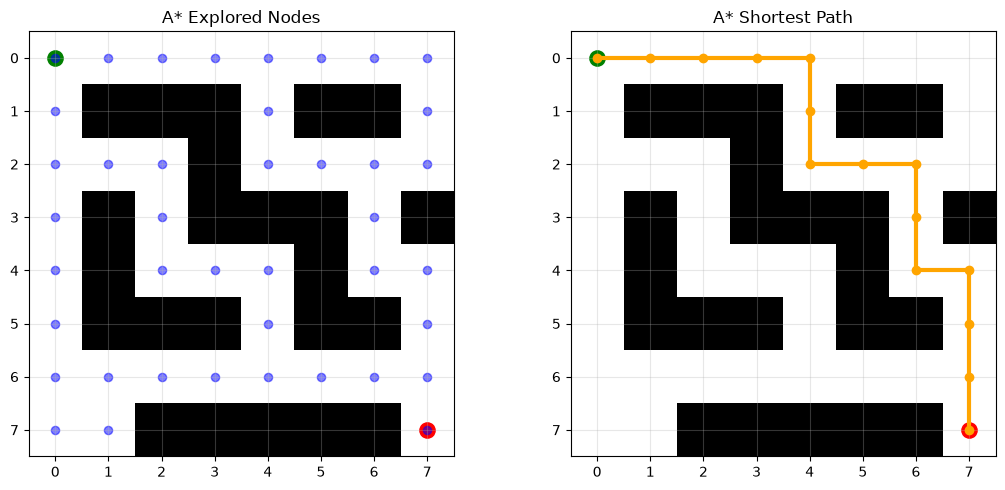

In [4]:
import heapq
import matplotlib.pyplot as plt

# 1. Grid (0 = free, 1 = obstacle)
grid = [
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0, 1, 1, 0],
    [0, 0, 0, 1, 0, 0, 0, 0],
    [0, 1, 0, 1, 1, 1, 0, 1],
    [0, 1, 0, 0, 0, 1, 0, 0],
    [0, 1, 1, 1, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0, 0],
    [0, 0, 1, 1, 1, 1, 1, 0],
]

start = (0, 0)
goal = (7, 7)


# 2. Heuristic: Manhattan distance
# domain specific
def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


# 3. A* Search
def astar(grid, start, goal):
    queue = [(heuristic(start, goal), 0, start)]
    costs = {start: 0}
    paths = {start: [start]}
    explored = []

    while queue:
        f, g, node = heapq.heappop(queue)

        if g > costs[node]:
            continue

        explored.append(node)

        if node == goal:
            return paths[node], g, explored

        # Explore 4 neighbors
        for dr, dc in [(0, 1), (1, 0), (0, -1), (-1, 0)]:
            r, c = node[0] + dr, node[1] + dc

            if 0 <= r < len(grid) and 0 <= c < len(grid[0]):
                if grid[r][c] == 1:
                    continue

                neighbor = (r, c)
                new_cost = g + 1

                if new_cost < costs.get(neighbor, float("inf")):
                    costs[neighbor] = new_cost
                    paths[neighbor] = paths[node] + [neighbor]
                    # in UCS
                    # priority = new_cost
                    priority = new_cost + heuristic(neighbor, goal)  # compared to UCS
                    heapq.heappush(queue, (priority, new_cost, neighbor))

    return None, float("inf"), explored


# 4. Run A*
path, cost, explored = astar(grid, start, goal)

print("Shortest path:", path)
print("Total cost:", cost)
print("Explored nodes:", len(explored))


# 5. Visualization
fig, ax = plt.subplots(1, 2, figsize=(11, 5))

for a in ax:
    a.imshow(grid, cmap="Greys", vmin=0, vmax=1)
    a.scatter(start[1], start[0], c="green", s=120, label="Start")
    a.scatter(goal[1], goal[0], c="red", s=120, label="Goal")
    a.set_xticks(range(len(grid[0])))
    a.set_yticks(range(len(grid)))
    a.grid(alpha=0.3)

# Explored nodes
ax[0].scatter(
    [p[1] for p in explored], [p[0] for p in explored], c="blue", s=35, alpha=0.5
)
ax[0].set_title("A* Explored Nodes")

# Optimal path
if path:
    ax[1].plot(
        [p[1] for p in path], [p[0] for p in path], "o-", color="orange", linewidth=3
    )
ax[1].set_title("A* Shortest Path")

plt.tight_layout()
plt.show()

Key to make it consistent: **relaxation**: reduce the cost of actions from infinity to finite values

compute a relaxed version of the problem as $h(n)$ (eg. remove some barriers in the original problem), whose relaxation should be in a structured way.

**reverse problem**: future_cost(n) = past_cost(n) in the reverse problem


## Markov Decision Process (MDP)


MDP generalizes search problems

Key difference: actions may have stochastic outcomes (eg. rolling a dice)

introduce **uncertainty**

- **Markov chains**: the past and future are independent given the state
- **decision**: an agent taking actions
- **process**: things happen sequentially over time


example: flaky tram problem

- location 1 to n
- walking from i to i+1 takes 1 minute
- taking a tram from i to 2i takes 2 minute _with probability p_
- goal: reach location n in the least expected time

mathmetically,

- Action(s): all possible actions from state s (a distribution over next states)
- Reward(s, a, s'): the reward of taking action a in state s and ending up in state s' (equals minus cost)
- T(s, a, s'): the probability of ending up in state s' after taking action a from state s. for all s', $\sum_{s'} T(s, a, s') = 1$

**policy**: a function that maps state to action; no matter what state the agent is in, it will tell the next action to take.

to evaluate a policy, we use


### **Rollout**

a simulation of the policy in an MDP.

Each rollout generates a **utility**, which is a **discounted** sum of rewards.

**discounting**: an evaluation of how important the future is

- generally represented by a discount factor $\gamma \in [0, 1]$
- discount = 1: the future is as important as the present
- discount = 0: the future does not matter at all
- discount usually $> 0.5$
- the higher the discount factor, the more important the future is (want to get a better long-term reward)

**value**: the expected utility of a state under a policy = the average utilities of rollouts (**monte carlo policy evaluation**)

$V_n(s)$: expected utility of starting in state s and following policy n

error = $\frac{1}{\sqrt{N}}$, where N is the number of rollouts


In [35]:
from dataclasses import dataclass
import numpy as np


@dataclass
class Step:
    state: int
    action: str
    reward: float
    probability: float


@dataclass
class MDP:
    num_locs: int
    failure_prob: float
    discount: float = 1.0

    def get_start_state(self):
        raise NotImplementedError  # let the subclass implement this method

    def get_successors(self, state):
        raise NotImplementedError

    def is_end_state(self, state):
        raise NotImplementedError


class FlakyTramMDP(MDP):
    def __init__(self, num_locs, failure_prob):
        self.num_locs = num_locs
        self.failure_prob = failure_prob

    def get_start_state(self):
        return 1

    def get_successors(self, state):
        successors = []
        # Walking action
        if state + 1 <= self.num_locs:
            successors.append(
                Step(action="walk", state=state + 1, reward=-1, probability=1.0)
            )  # reward = -cost
        # Tram action
        if state * 2 <= self.num_locs:
            # move successfully
            successors.append(
                Step(
                    action="tram",
                    state=state * 2,
                    reward=-2,
                    probability=1.0 - self.failure_prob,
                )
            )
            successors.append(
                Step(
                    action="tram", state=state, reward=-2, probability=self.failure_prob
                )
            )
        return successors

    def is_end_state(self, state):
        return state == self.num_locs


mdp = FlakyTramMDP(
    num_locs=10, failure_prob=0.4
)  # probability is the key difference between MDP and search problems
state = mdp.get_start_state()
print(f"Start state: {state}")
successors = mdp.get_successors(state)
print(f"Successors: {successors}")

Start state: 1
Successors: [Step(state=2, action='walk', reward=-1, probability=1.0), Step(state=2, action='tram', reward=-2, probability=0.6), Step(state=1, action='tram', reward=-2, probability=0.4)]


In [36]:
@dataclass
class Policy:
    def get_action(self, state):
        raise NotImplementedError


@dataclass
class Rollout:
    steps: list[Step]
    utility: float = 0.0


def compute_utility(steps, discount: float) -> float:
    rewards = [
        step.reward * discount**i for i, step in enumerate(steps)
    ]  # the discounting way is problem-specific
    utility = sum(rewards)
    return utility


def generate_rollout(mdp: MDP, policy: Policy) -> Rollout:
    steps = []
    state = mdp.get_start_state()

    while not mdp.is_end_state(state):
        action = policy.get_action(state)
        successors = [
            successor
            for successor in mdp.get_successors(state)
            if successor.action == action
        ]
        probs = [s.probability for s in successors]
        # find the step corresponding to the chosen action
        choice = np.random.choice(len(successors), p=probs)
        step = successors[choice]
        steps.append(step)
        state = step.state
    return Rollout(steps=steps, utility=compute_utility(steps, mdp.discount))


def monte_carlo_evaluation(mdp: MDP, policy: Policy, num_rollouts: int) -> float:
    total_utility = 0.0
    utilities = [generate_rollout(mdp, policy).utility for _ in range(num_rollouts)]
    average_utility = np.mean(utilities)
    return average_utility


class TramIfPossiblePolicy(Policy):
    def get_action(self, state):
        return "tram" if state * 2 <= mdp.num_locs else "walk"


tram_if_possible_policy = TramIfPossiblePolicy()


class WalkOnlyPolicy(Policy):
    def get_action(self, state):
        return "walk"


walk_only_policy = WalkOnlyPolicy()

print(
    "tram_if_possible_policy = ",
    monte_carlo_evaluation(mdp, policy=tram_if_possible_policy, num_rollouts=20),
)
print(
    "walk_only_policy = ",
    monte_carlo_evaluation(mdp=mdp, policy=walk_only_policy, num_rollouts=20),
)

tram_if_possible_policy =  -12.3
walk_only_policy =  -9.0


### Policy Evaluation

**Q-values**: $$Q(s, a, V) = \sum_{s'} T(s, a, s')[R(s, a, s')+\gamma V(s')]$$, s' is all successors of state s after taking action a

measures value of taking action a in state s and obtains some value V, where V(s) is the value of some policy from state s

compured to rollout:

- do this for all states
- rinse and repeat with the values (**bootstrap**)

**convergence**:

we compute the distance between the new value and the old value (the maximum difference over all states)

stop when the distance is small enough ($<\epsilon$).

**policy evaluation**: compute the value of a policy $\pi$ by iteratively computing the value of each state under the policy.

$$
V^{(t)}_{\pi} (x) = Q(s, \pi(s), s') = \sum_{s'} T(s, \pi(s), s')[R(s, \pi(s), s')+\gamma V^{(t-1)}_{\pi}(s')]
$$,

where $\pi(s)$ is the action taken in state s under policy $\pi$.

in this process, we are trying to reach all the states, and distance decreases exponentially
$$


In [38]:
def get_initial_values(mdp: MDP) -> dict[int, float]:
    values = {}
    for state in range(1, mdp.num_locs):
        values[state] = -100  # we don't know
    values[mdp.num_locs] = 0  # end state has utility 0
    return values


values = get_initial_values(mdp)
print(f"Initial values: {values}")


def compute_q_value(
    successors: list[Step], discount: float, values: dict[int, float]
) -> float:
    """compute the Q-value for a list of successors (possible transitions) given the discount factor and the current value function"""

    weighted_utilities = []
    # utility = \sum reward(s') + discount * V(s')
    # V(s') is the estimated value of the next state s' (the successor state)
    for step in successors:
        utility = step.reward + discount * values[step.state]
        weighted_utilities.append(step.probability * utility)
    value = sum(weighted_utilities)
    return value


def compute_distance(values: dict[int, float], new_values: dict[int, float]) -> float:
    """compute the distance between old values and new values"""
    distance = max(abs(values[state] - new_values[state]) for state in values)
    return distance


@dataclass
class PolicyEvaluationResult:
    values: dict[int, float]
    distances: list[float]


def policy_evaluation(
    mdp: MDP, policy: Policy, threshold: float, max_iters: int = 100
) -> PolicyEvaluationResult:
    """compute the value function for a given policy using iterative policy evaluation"""
    values = get_initial_values(mdp)
    distances = []
    for iter in range(max_iters):
        new_values = {}
        for state in values:
            if mdp.is_end_state(state):
                new_values[state] = 0
            else:
                action = policy.get_action(state)
                successors = [
                    successor
                    for successor in mdp.get_successors(state)
                    if successor.action == action
                ]
                new_values[state] = compute_q_value(successors, mdp.discount, values)
        distance = compute_distance(values, new_values)
        distances.append(distance)
        values = new_values
        print(f"Iteration {iter + 1}: distance = {distance:.4f}, values = {values}")
        if distance < threshold:
            break
    return PolicyEvaluationResult(values=values, distances=distances)


print("Evaluating tram_if_possible_policy...")
values_tram_if_possible_policy = policy_evaluation(
    mdp, policy=tram_if_possible_policy, threshold=1e-5, max_iters=100
)
print("Evaluating walk_only_policy...")
values_walk_only_policy = policy_evaluation(
    mdp, policy=walk_only_policy, threshold=1e-5, max_iters=100
)
print(
    "values_tram_if_possible_policy = ",
    values_tram_if_possible_policy,
)
print(
    "values_walk_only_policy = ",
    values_walk_only_policy,
)

Initial values: {1: -100, 2: -100, 3: -100, 4: -100, 5: -100, 6: -100, 7: -100, 8: -100, 9: -100, 10: 0}
Evaluating tram_if_possible_policy...
Iteration 1: distance = 99.0000, values = {1: -102.0, 2: -102.0, 3: -102.0, 4: -102.0, 5: -42.00000000000001, 6: -101.0, 7: -101.0, 8: -101.0, 9: -1.0, 10: 0}
Iteration 2: distance = 99.0000, values = {1: -104.0, 2: -104.0, 3: -103.4, 4: -103.4, 5: -18.800000000000004, 6: -102.0, 7: -102.0, 8: -2.0, 9: -1.0, 10: 0}
Iteration 3: distance = 99.0000, values = {1: -106.0, 2: -105.64000000000001, 3: -104.56, 4: -44.56, 5: -9.520000000000001, 6: -103.0, 7: -3.0, 8: -2.0, 9: -1.0, 10: 0}
Iteration 4: distance = 99.0000, values = {1: -107.784, 2: -70.99200000000002, 3: -105.624, 4: -21.024, 5: -5.808000000000001, 6: -4.0, 7: -3.0, 8: -2.0, 9: -1.0, 10: 0}
Iteration 5: distance = 58.9744, values = {1: -87.70880000000001, 2: -43.01120000000001, 3: -46.6496, 4: -11.6096, 5: -4.323200000000001, 6: -4.0, 7: -3.0, 8: -2.0, 9: -1.0, 10: 0}
Iteration 6: distanc

### Value Iteration

To compute values of the optimal policy, while constructs the optimal policy as a side effect.

value iteration recurrence:

$$
V^{*}(s) = \max_{a} Q(s, a, V^{*}) = \max_{a} \sum_{s'} T(s, a, s')[R(s, a, s')+\gamma V^{*}(s')]
$$

Key difference: optimize over actions a instead of taking policy action $\pi(s)$

This is deterministic for MDPs.

In [44]:
def get_action_successors(mdp: MDP, state: int) -> dict[str, list[Step]]:
    """get the successors for each action in a given state"""
    action_successors = {}
    for step in mdp.get_successors(state):
        if step.action not in action_successors:
            action_successors[step.action] = []
        action_successors[step.action].append(step)
    return action_successors


def value_iteration_for_state(
    mdp: MDP, state: int, values: dict[int, float]
) -> tuple[float, str]:
    """compute optimal value V'*' and optimal policy pi'*'"""
    actions = []
    q_values = []
    for action, successors in get_action_successors(mdp, state).items():
        q_value = compute_q_value(successors, mdp.discount, values)
        actions.append(action)
        q_values.append(q_value)
    value = np.max(q_values)
    action = actions[np.argmax(q_values)]
    return value, action


@dataclass
class ValueIterationResult:
    values: dict[int, float]
    pi: dict[int, str]
    distances: list[float]


def value_iteration(
    mdp: MDP, threshold: float, max_iters: int = 100
) -> ValueIterationResult:
    """compute the optimal value function and optimal policy using value iteration"""
    values = get_initial_values(mdp)
    pi: dict[int, str] = {}  # record the optimal action for each state
    distances = []
    for iter in range(max_iters):
        new_values = {}
        for state in values:
            if mdp.is_end_state(state):
                new_values[state] = 0
                continue
            value, action = value_iteration_for_state(mdp, state, values)
            new_values[state] = value
            pi[state] = action
        distance = compute_distance(values, new_values)
        distances.append(distance)
        print(f"Iteration {iter + 1}: distance = {distance:.4f}, values = {new_values}")
        values = new_values
        if distance < threshold:
            break
    return ValueIterationResult(values=values, pi=pi, distances=distances)


value_iteration_result = value_iteration(mdp, threshold=1e-5, max_iters=100)
print("Optimal values:", value_iteration_result.values)
print("Optimal policy:", value_iteration_result.pi)

Iteration 1: distance = 99.0000, values = {1: np.float64(-101.0), 2: np.float64(-101.0), 3: np.float64(-101.0), 4: np.float64(-101.0), 5: np.float64(-42.00000000000001), 6: np.float64(-101.0), 7: np.float64(-101.0), 8: np.float64(-101.0), 9: np.float64(-1.0), 10: 0}
Iteration 2: distance = 99.0000, values = {1: np.float64(-102.0), 2: np.float64(-102.0), 3: np.float64(-102.0), 4: np.float64(-43.00000000000001), 5: np.float64(-18.800000000000004), 6: np.float64(-102.0), 7: np.float64(-102.0), 8: np.float64(-2.0), 9: np.float64(-1.0), 10: 0}
Iteration 3: distance = 99.0000, values = {1: np.float64(-103.0), 2: np.float64(-68.60000000000001), 3: np.float64(-44.00000000000001), 4: np.float64(-19.800000000000004), 5: np.float64(-9.520000000000001), 6: np.float64(-103.0), 7: np.float64(-3.0), 8: np.float64(-2.0), 9: np.float64(-1.0), 10: 0}
Iteration 4: distance = 99.0000, values = {1: np.float64(-69.60000000000001), 2: np.float64(-41.32000000000001), 3: np.float64(-20.800000000000004), 4: np.